# Fitting a learned predictor on nine campaigns and predicting the tenth

**Question:** What does a learned model predict for a campaign it was not trained on?

**Level 1: Fundamentals** · Needs: 04-benchmark-protocol/01-three-ways-to-split-the-same-97-blasts · Reading time: about 25 minutes

## Objectives

A blast engineer who picks a predictor is not asking how well it remembers the blasts it was built from. The question is what it says at the next mine, where nobody has measured a fragment size yet. This notebook puts that question to the six learned predictors of the ladder: it fits them on nine campaigns, hides the tenth and compares what they say with what was measured.

By the end you will have:

- built the leave-Enusa-out split with the engine and seen how different the ten campaigns are from each other;
- fitted gradient boosting on 85 blasts, scored it inside its training data and on the 12 Enusa blasts, and read the gap;
- repeated the exercise for all six learned predictors and the null, and read which of them beat a constant guess;
- understood why a variance explained below zero is a finding and not a bug.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

The cell below imports the packages, prints the installed versions so that the output records which engine produced every number, and loads the 97 blasts of the corpus. It also defines `Table`, a few lines that show a list of rows as a Markdown table in Jupyter and as aligned text anywhere else.

In [1]:
# Imports, package versions and the corpus loader
from importlib.metadata import version
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
print(len(train), "blasts from", len({b.site for b in train}), "campaigns")

class Table:
    """Rows under a header, shown as a Markdown table"""

    def __init__(self, header, rows):
        self.header = list(header)
        self.rows = [[str(cell) for cell in row] for row in rows]

    def _repr_markdown_(self):
        lines = ["| " + " | ".join(self.header) + " |", "|" + "---|" * len(self.header)]
        lines += ["| " + " | ".join(row) + " |" for row in self.rows]
        return "\n".join(lines)

    __repr__ = _repr_markdown_

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2
97 blasts from 10 campaigns


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97 blasts, ten campaigns | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The six learned predictors as published | Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (network); Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (support vector, rbf); Sui et al. 2025, https://doi.org/10.3390/app15031254 (support vector, polynomial; forest; boosting; stacking) | the methods are cited, the engine implements them | `bf.default_arms()` |

Nothing else is read: the committed Enusa case artifact is compared with this run by the product's tests, not here.

## Method

Every predictor of the engine has the same two verbs. `fit(training blasts)` learns from rows that carry a measured size, and `predict(blasts)` returns, for each blast, a mean size `x50` in metres or a refusal with its reason. A closed-form predictor ignores `fit`; a learned one does its work there. The inputs are the seven design and rock quantities of the corpus (the ratios S/B, H/B, B/D and T/B, the powder factor, the in situ block size and the rock modulus), and the output is the mean fragment size.

The protocol is the one that respects the structure of the data. Rows within a campaign share a rock mass, a rig, an explosive supply and an operator, so they are not independent draws. Holding out a whole campaign gives the learner the situation a user faces: nine mines to learn from, a tenth to predict. The score is `r2_identity`, the variance explained about the 1:1 line, `1 - SS_res / SS_tot`. It is 1 for a perfect prediction, 0 when the predictor is no better than the mean of the measurements it is scored on, and it can be arbitrarily negative. Beside every learned predictor the notebook scores the null, which predicts the mean size of the training rows for every blast: a learner that cannot beat the null has learned nothing that transfers.

### Step 1: the split, and how unlike the campaigns are

`leave_one_site_out` yields one split per campaign, with the training blasts of the other nine and the held-out blasts of the tenth. The cell picks the Enusa split and then tabulates the measured sizes of every campaign, so that the reader sees what the learner is asked to bridge.

In [2]:
# Hold out Enusa: the split that leave-one-site-out makes for that campaign
fold = next(split for split in bf.leave_one_site_out(train) if split.test[0].site == "Enusa")
fit_rows = fold.train
test_rows = fold.test
print(fold.protocol, "|", len(fit_rows), "training blasts from", len({b.site for b in fit_rows}),
      "campaigns", "|", len(test_rows), "held-out blasts")
sizes = {}
for blast in train:
    sizes.setdefault(blast.site, []).append(blast.x50_m)
rows = [(site, len(v), f"{min(v):.2f}", f"{np.mean(v):.3f}", f"{max(v):.2f}") for site, v in sorted(sizes.items())]
Table(["campaign", "n", "min x50 (m)", "mean x50 (m)", "max x50 (m)"], rows)

leave-out-Enusa | 85 training blasts from 9 campaigns | 12 held-out blasts


| campaign | n | min x50 (m) | mean x50 (m) | max x50 (m) |
|---|---|---|---|---|
| Akdaglar | 22 | 0.14 | 0.171 | 0.22 |
| Dongri-Buzurg | 9 | 0.23 | 0.413 | 0.76 |
| Enusa | 12 | 0.26 | 0.396 | 0.64 |
| Miami | 6 | 0.02 | 0.080 | 0.10 |
| Mrica | 11 | 0.13 | 0.166 | 0.21 |
| Murgul | 7 | 0.23 | 0.311 | 0.38 |
| Ozmert | 7 | 0.12 | 0.191 | 0.30 |
| Reocin | 10 | 0.44 | 0.616 | 0.96 |
| Reocin-UG | 6 | 0.51 | 0.593 | 0.69 |
| Soma | 7 | 0.15 | 0.224 | 0.28 |

The next cell draws the table above as a picture: one column of points per campaign, ordered by mean size, with the mean as a black bar and Enusa in orange. Look at how far apart the campaign levels are compared with the spread inside each one.

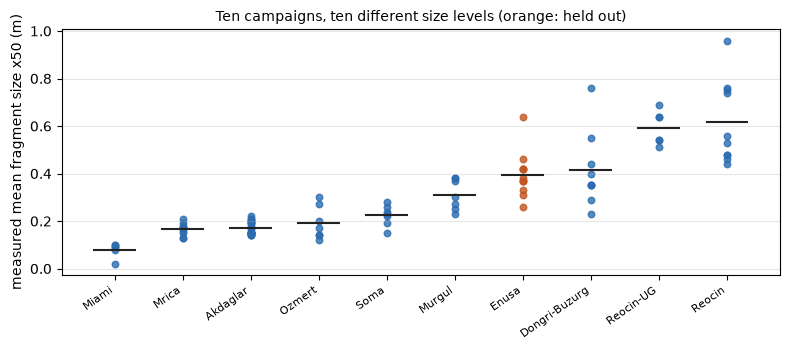

In [3]:
# Measured mean size by campaign; Enusa is the one the learners never see
order = sorted(sizes, key=lambda site: np.mean(sizes[site]))
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, site in enumerate(order):
    color = "#c05621" if site == "Enusa" else "#2b6cb0"
    ax.scatter(np.full(len(sizes[site]), k), sizes[site], s=22, color=color, alpha=0.8)
    ax.plot([k - 0.3, k + 0.3], [np.mean(sizes[site])] * 2, color="#222", lw=1.5)
ax.set_xticks(range(len(order)), order, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("measured mean fragment size x50 (m)")
ax.set_title("Ten campaigns, ten different size levels (orange: held out)", fontsize=10)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

**What the figure shows.** The ten campaigns sit at very different size levels: Miami's six blasts average 0.080 m and Reocin's ten average 0.616 m, a factor of almost eight, and within Enusa (orange) the twelve blasts run from 0.26 m to 0.64 m around a mean of 0.396 m. **What it does not show:** why the levels differ. The cause is a mix of rock, explosive and measurement method that the seven inputs only partly describe. **What follows:** a learner that has seen nine of these levels must place the tenth from the inputs alone, and the next steps measure how well it does.

### Step 2: one learned predictor, in sample and on the campaign left out

Gradient boosting is the simplest learned predictor to read: a sum of small regression trees, each correcting the error of the sum before it (Sui et al. 2025, https://doi.org/10.3390/app15031254). The cell fits it on the 85 training blasts, then scores it twice: on the rows it was fitted on and on the 12 Enusa blasts it never saw. The table lists the Enusa predictions blast by blast.

In [4]:
# Fit gradient boosting on the nine campaigns and score it in sample and on Enusa
boosting = bf.default_arms()["xgboost"]().fit(fit_rows)
predictions = boosting.predict(test_rows)
in_sample = bf.score(fit_rows, boosting.predict(fit_rows))
held_out = bf.score(test_rows, predictions)
print(f"r2 in sample = {in_sample.r2_identity:.3f}   RMSE = {in_sample.rmse_m:.3f} m")
print("standard deviation of the measured Enusa sizes", f"= {np.std([b.x50_m for b in test_rows]):.3f} m")
print(f"r2 on Enusa = {held_out.r2_identity:.3f}   RMSE = {held_out.rmse_m:.3f} m   bias = {held_out.bias_m:+.3f} m")
rows = [(b.blast_id, f"{b.x50_m:.2f}", f"{p.x50_m:.3f}", f"{p.x50_m - b.x50_m:+.3f}") for b,
    p in zip(test_rows, predictions)]
Table(["blast", "measured (m)", "predicted (m)", "error (m)"], rows)

r2 in sample = 0.998   RMSE = 0.008 m
standard deviation of the measured Enusa sizes = 0.090 m
r2 on Enusa = -0.579   RMSE = 0.114 m   bias = +0.067 m


| blast | measured (m) | predicted (m) | error (m) |
|---|---|---|---|
| En1 | 0.37 | 0.460 | +0.090 |
| En2 | 0.37 | 0.460 | +0.090 |
| En3 | 0.33 | 0.460 | +0.130 |
| En4 | 0.42 | 0.463 | +0.043 |
| En5 | 0.46 | 0.460 | -0.000 |
| En6 | 0.37 | 0.482 | +0.112 |
| En7 | 0.64 | 0.459 | -0.181 |
| En8 | 0.42 | 0.463 | +0.043 |
| En9 | 0.26 | 0.463 | +0.203 |
| En10 | 0.42 | 0.459 | +0.039 |
| En11 | 0.31 | 0.462 | +0.152 |
| En12 | 0.38 | 0.462 | +0.082 |

**What the output shows.** Inside its training data the model is almost exact (r2 0.998, RMSE 0.008 m). On Enusa the same model scores r2 -0.579 with an RMSE of 0.114 m and a bias of +0.067 m, so it over-predicts on average. The table explains the shape of that error: the twelve predictions sit between 0.459 m and 0.482 m while the measured sizes run from 0.26 m to 0.64 m. The model has placed Enusa at one size level and cannot tell its blasts apart, so it is too coarse for En9 (0.26 m measured, 0.463 m predicted) and too fine for En7 (0.64 m measured, 0.459 m predicted). **What it does not show:** that the fit is wrong. It reproduces the training campaigns, which is all that fitting guarantees.

### Step 3: all six learned predictors, and the null

The cell fits every predictor of the learned tier on the same nine campaigns: the back-propagation network of Kulatilake et al. 2012, two support vector regressors, a random forest, gradient boosting and a stacking ensemble that combines the forest and the boosted trees. It adds the null, scores each one inside the training data and on Enusa, and draws the root-mean-square error of both, with the null's Enusa error as a reference line.

In [5]:
# Fit the six learned predictors and the null on the same nine campaigns
factories = bf.default_arms()
learned = [name for name, make in factories.items() if make().tier == "learned"]
fitted = {name: factories[name]().fit(fit_rows) for name in learned}
fitted["null"] = bf.NullModel().fit(fit_rows)
scores = {}
for name, model in fitted.items():
    scores[name] = (bf.score(fit_rows, model.predict(fit_rows)), bf.score(test_rows, model.predict(test_rows)))
rows = [(name, f"{a.r2_identity:.3f}", f"{a.rmse_m:.3f}", f"{b.r2_identity:.3f}", f"{b.rmse_m:.3f}",
    f"{b.bias_m:+.3f}")
        for name, (a, b) in scores.items()]
Table(["predictor", "r2 in sample", "RMSE in sample (m)", "r2 Enusa", "RMSE Enusa (m)", "bias Enusa (m)"], rows)

| predictor | r2 in sample | RMSE in sample (m) | r2 Enusa | RMSE Enusa (m) | bias Enusa (m) |
|---|---|---|---|---|---|
| published-neural-net | 0.998 | 0.009 | -14.163 | 0.352 | +0.334 |
| svr-rbf | 0.939 | 0.048 | -6.644 | 0.250 | +0.206 |
| svr-poly | 0.708 | 0.105 | -37.358 | 0.559 | +0.523 |
| random-forest | 0.974 | 0.031 | -0.482 | 0.110 | +0.056 |
| xgboost | 0.998 | 0.008 | -0.579 | 0.114 | +0.067 |
| stacking | 0.998 | 0.008 | -0.583 | 0.114 | +0.067 |
| null | 0.000 | 0.194 | -1.388 | 0.140 | -0.106 |

The next cell turns the scoreboard into bars: the RMSE of each predictor on the rows it was fitted on (blue) and on Enusa (orange), with the null's Enusa error as a dashed line. The question to ask of it is how many orange bars rise above the dashed line.

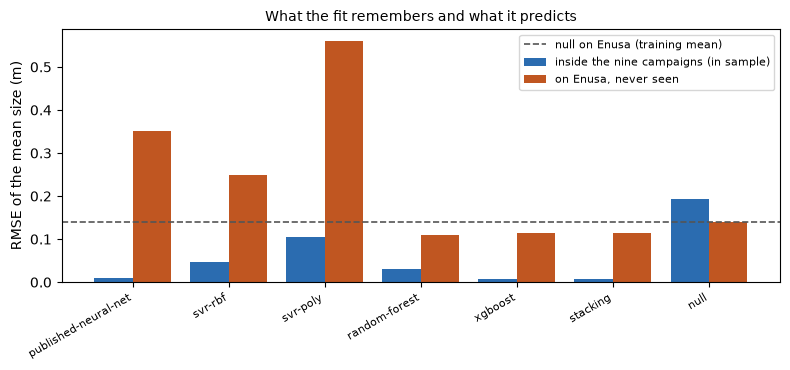

In [6]:
# Error inside the training campaigns against error on the campaign left out
names = list(scores)
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(x - 0.2, [scores[n][0].rmse_m for n in names], 0.4, color="#2b6cb0",
    label="inside the nine campaigns (in sample)")
ax.bar(x + 0.2, [scores[n][1].rmse_m for n in names], 0.4, color="#c05621", label="on Enusa, never seen")
ax.axhline(scores["null"][1].rmse_m, color="#555", ls="--", lw=1.2, label="null on Enusa (training mean)")
ax.set_xticks(x, names, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("RMSE of the mean size (m)")
ax.set_title("What the fit remembers and what it predicts", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**What the figure shows.** Blue bars, the error inside the nine training campaigns, are all small: from 0.008 m for the network and the boosted trees to 0.105 m for the polynomial support vector regressor. Orange bars, the error on Enusa, are larger for every learned predictor, and for three of them they are above the dashed line, which is the null's error on Enusa (0.140 m): the network (0.352 m), the radial support vector regressor (0.250 m) and the polynomial one (0.559 m) are worse than predicting the training mean. The forest (0.110 m), boosting (0.114 m) and stacking (0.114 m) are below that line. **What it does not show:** a ranking of the predictors, because it is one campaign of ten.

### Step 4: where each predictor puts the twelve blasts

The last figure plots, for each learned predictor, its Enusa predictions against the measurements. A perfect predictor would lie on the 1:1 line; a predictor that has learned nothing about the differences inside the campaign would draw a horizontal band.

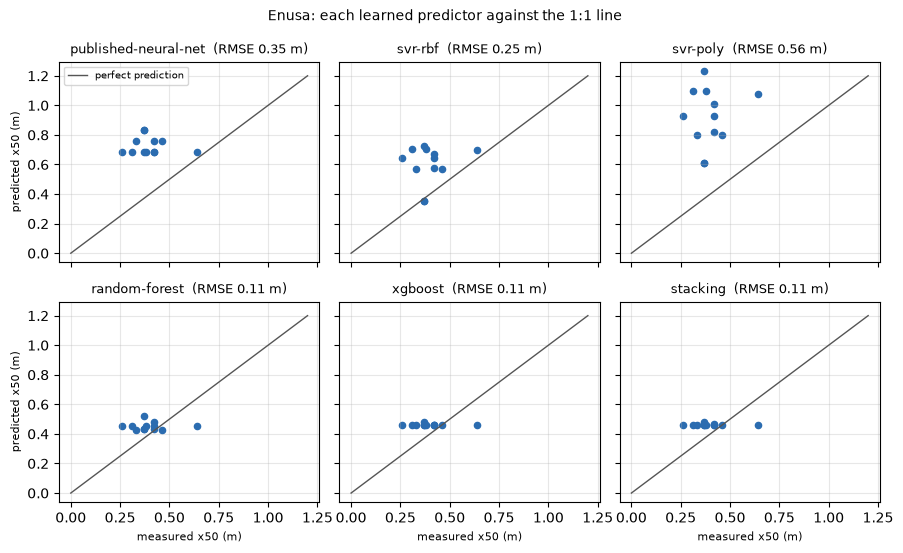

In [7]:
# Predicted against measured size on Enusa, one panel per learned predictor
measured = np.array([b.x50_m for b in test_rows])
fig, axes = plt.subplots(2, 3, figsize=(9, 5.6), sharex=True, sharey=True)
for ax, name in zip(axes.flat, learned):
    predicted = np.array([p.x50_m for p in fitted[name].predict(test_rows)])
    ax.scatter(measured, predicted, s=20, color="#2b6cb0")
    ax.plot([0, 1.2], [0, 1.2], color="#555", lw=1, label="perfect prediction")
    ax.set_title(f"{name}  (RMSE {scores[name][1].rmse_m:.2f} m)", fontsize=9)
    ax.grid(alpha=0.3)
axes[1, 0].set_xlabel("measured x50 (m)", fontsize=8)
axes[1, 1].set_xlabel("measured x50 (m)", fontsize=8)
axes[1, 2].set_xlabel("measured x50 (m)", fontsize=8)
axes[0, 0].set_ylabel("predicted x50 (m)", fontsize=8)
axes[1, 0].set_ylabel("predicted x50 (m)", fontsize=8)
axes[0, 0].legend(fontsize=7, loc="upper left")
fig.suptitle("Enusa: each learned predictor against the 1:1 line", fontsize=10)
fig.tight_layout()
plt.show()

**What the figure shows.** The three tree-based panels (forest, boosting, stacking) draw nearly horizontal bands near 0.46 m, which cross the 1:1 line in the middle of the measured range: they place all twelve blasts at about the same size and miss the spread. The network, the radial support vector regressor and the polynomial one draw scattered clouds far above the line, which is the positive bias of +0.334 m, +0.206 m and +0.523 m in the table of step 3. **What it does not show:** how these predictors behave on the other nine campaigns, where the level may be right and the errors differ. **What follows:** the error on a new campaign is dominated by getting the level wrong, and level is exactly what nine other campaigns cannot teach.

## Results

**Answer:** a learned model predicts a campaign it has not seen about as well as a constant, and usually worse. On Enusa the best of the six, the random forest, scores r2 -0.482 with an RMSE of 0.110 m, against r2 -1.388 and 0.140 m for the null; gradient boosting (-0.579, 0.114 m) and stacking (-0.583, 0.114 m) are close behind. The network (-14.163, 0.352 m), the radial support vector regressor (-6.644, 0.250 m) and the polynomial one (-37.358, 0.559 m) are worse than the null by a wide margin. Every one of them is nearly exact inside its training campaigns (r2 between 0.708 and 0.998), so the distance between 0.998 and -0.579 for boosting is the price of the transfer, not a defect of the fit.

Why the scores are so negative: the twelve measured sizes of Enusa have a standard deviation of only 0.090 m, so an RMSE of 0.114 m already exceeds the spread that r2 is measured against, and a bias of a few decimetres, as for the network or the polynomial regressor, makes r2 collapse. RMSE and bias are the fairer read for one campaign, and they say the same thing in metres.

**What this does not show.** One campaign is one test, and Enusa is not typical. The next notebook repeats the exercise with each of the ten campaigns held out in turn and pools the result, which is the only score the product leads with. Nor does it show that learning cannot help: it shows that these six learners, on 85 rows, gain nothing at a new mine over a constant.

## Summary

- A learned predictor is fitted on nine campaigns and asked about the tenth; the engine's `leave_one_site_out` builds that split.
- Inside the training campaigns every learned predictor is nearly exact (boosting: r2 0.998); on Enusa the same boosting scores -0.579 and the null -1.388.
- The tree-based predictors place all twelve Enusa blasts at one size level (0.459 m to 0.482 m against 0.26 m to 0.64 m measured); the network and the support vector regressors are far worse than the null.
- Next: notebook 02 runs all fourteen predictors through every campaign and explains where each one refuses to answer.

## References

- Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (the back-propagation network and its hold-out)
- Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (support vector regression, rbf kernel; the classical equation)
- Sui, Zhou, Zhao, Yang and Zou 2025, https://doi.org/10.3390/app15031254 (support vector polynomial, forest, boosting, stacking)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus and the published regression)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/